# Dados de cheias do Zenodo (UFRGS/IPH)

Leitura do GeoPackage *Banco de dados das cheias na Região Hidrográfica do Lago Guaíba*, v1.2 —
https://zenodo.org/records/13227745 (CC-BY-4.0), baixado por `scripts/coleta_zenodo.py`.

Perguntas:
1. Quais bairros de Porto Alegre alagaram em 2024 e nas cheias anteriores?
2. A simulação do INCT concorda com as manchas de inundação do Zenodo?
3. A água medida em campo em maio de 2024 bate com a mancha simulada?

Toda alteração feita nos dados está comentada no código com **ALTERAÇÃO**.

## Leitura dos dados

In [5]:
import json
import re
import unicodedata
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

PROJECT_DIR = Path.cwd() if (Path.cwd() / "dados").exists() else Path.cwd().parent
ORIGINAIS = PROJECT_DIR / "dados" / "originais"
GPKG = ORIGINAIS / "zenodo" / "cheias_rhguaiba_2024_db_v12.gpkg"

# Bairros de Porto Alegre (camada do GeoPackage)
bairros = gpd.read_file(GPKG, layer="poa_admin_bairros")

# Simulação do INCT em formato longo (uma linha por nível e bairro)
with open(ORIGINAIS / "INCT" / "data.json", encoding="utf-8") as f:
    raw = json.load(f)
inct = pd.DataFrame([
    {"nivel_m": float(nivel.removesuffix("m").replace("_", ".")), "bairro": bairro, **valores}
    for nivel, bs in raw.items()
    for bairro, valores in bs.items()
])
print("Bairros no GeoPackage:", len(bairros), "| CRS:", bairros.crs)
print("Bairros no INCT:", inct["bairro"].nunique())

Bairros no GeoPackage: 83 | CRS: EPSG:31982
Bairros no INCT: 94


## Limpeza: nomes dos bairros

O GeoPackage escreve `PASSO DAREIA` e o INCT `Passo D'Areia` (**formatos inconsistentes**).
Criamos uma coluna `chave` com o nome sem acento, sem apóstrofo e em minúsculas para juntar as duas bases.

In [6]:
def padroniza(nome):
    """Remove acentos e apóstrofos, deixa em minúsculas e com espaços simples."""
    sem_acento = unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode()
    sem_apostrofo = sem_acento.replace("'", "")
    return " ".join(re.sub(r"[^a-z0-9]+", " ", sem_apostrofo.lower()).split())

# ALTERAÇÃO: dois bairros têm nome diferente nas duas fontes; trocamos o nome do GeoPackage
# pelo nome usado no INCT (conferido manualmente no mapa de bairros).
NOMES_CORRIGIDOS = {"cel aparicio borges": "coronel aparicio borges", "sao jose": "vila sao jose"}

bairros["chave"] = bairros["nmbop"].map(padroniza).replace(NOMES_CORRIGIDOS)
inct["chave"] = inct["bairro"].map(padroniza)

so_no_inct = sorted(set(inct["chave"]) - set(bairros["chave"]))
print(f"Bairros do INCT sem polígono no GeoPackage ({len(so_no_inct)}):", so_no_inct)

Bairros do INCT sem polígono no GeoPackage (11): ['aberta dos morros', 'boa vista do sul', 'costa e silva', 'extrema', 'jardim europa', 'jardim leopoldina', 'parque santa fe', 'pitinga', 'santa rosa de lima', 'sao caetano', 'setimo ceu']


O GeoPackage usa a divisão antiga (83 bairros) e o INCT a nova, de 2016 (94 bairros).
Os 11 bairros acima não têm polígono, então **ficam fora das comparações** (dado faltante: removido).

### Área alagada total × nível do Guaíba

Soma da área alagada em todos os bairros. Quanto maior o nível, maior a área — mas até a cheia de 2015 (2,94 m)
já mostra ~90 km², porque as manchas incluem as ilhas e áreas úmidas que ficam sob água em qualquer cheia.

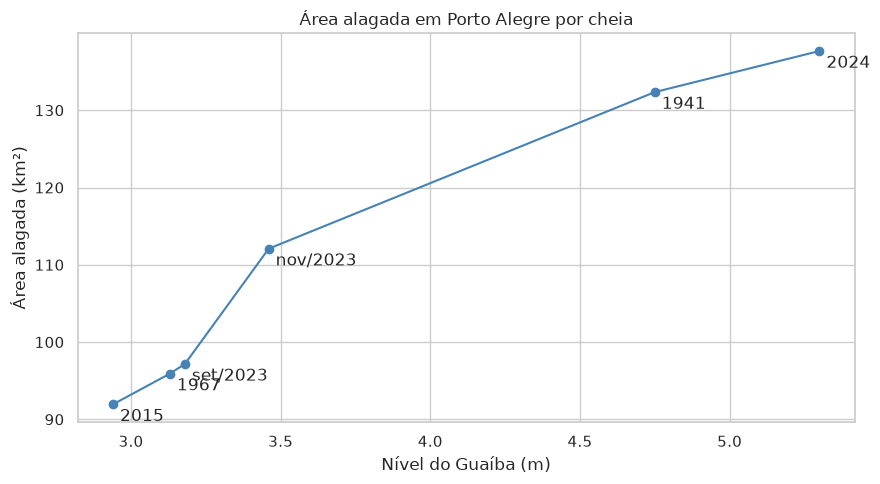

In [9]:
area_total = pd.DataFrame({
    "cheia": cheias,
    "nivel_m": [NIVEL[c] for c in cheias],
    "area_km2": [(alag[c] * alag["area_km2"] / 100).sum() for c in cheias],
}).sort_values("nivel_m")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(area_total["nivel_m"], area_total["area_km2"], marker="o", color="steelblue")
for _, linha in area_total.iterrows():
    ax.annotate(linha["cheia"], (linha["nivel_m"], linha["area_km2"]), textcoords="offset points", xytext=(5, -12))
ax.set_title("Área alagada em Porto Alegre por cheia")
ax.set_xlabel("Nível do Guaíba (m)")
ax.set_ylabel("Área alagada (km²)")
plt.tight_layout()
plt.show()

### Valores extremos em cada cheia

Os pontos fora das caixas são bairros muito diferentes dos demais. Aqui eles **não são erro**: são os bairros
da orla e das ilhas (ex.: Arquipélago), então **mantemos** esses valores.

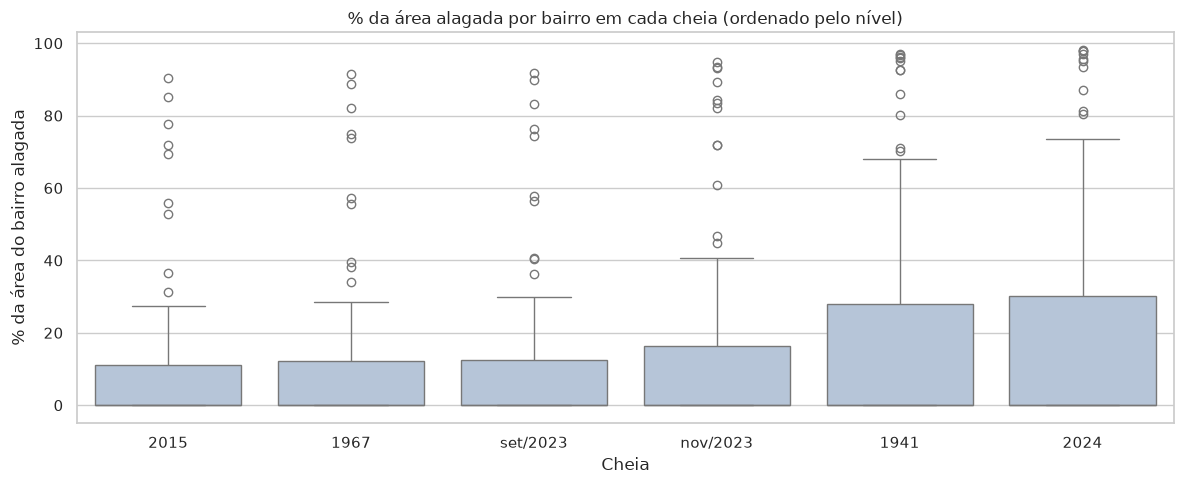

In [12]:
longo = alag.melt(id_vars="nmbop", value_vars=cheias, var_name="cheia", value_name="pct")

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=longo, x="cheia", y="pct", order=sorted(cheias, key=NIVEL.get), color="lightsteelblue", ax=ax)
ax.set_title("% da área alagada por bairro em cada cheia (ordenado pelo nível)")
ax.set_xlabel("Cheia")
ax.set_ylabel("% da área do bairro alagada")
plt.tight_layout()
plt.show()

## Comparação com o INCT

Juntamos a % de prédios afetados do INCT a **5,3 m** (nível mais próximo do pico) às manchas de 2024.
O `merge` com `how="inner"` mantém só os 83 bairros presentes nas duas bases.

In [28]:
inct_53 = inct.loc[inct["nivel_m"] == 5.3, ["chave", "bairro", "percentage"]]
inct_53 = inct_53.rename(columns={"percentage": "INCT 5,3m"})
comp = alag.merge(inct_53, on="chave", how="inner")
print(len(comp), "bairros comparados")

83 bairros comparados


### Mapa: observado × INCT

À esquerda, % da área alagada observada; à direita, % de prédios afetados segundo o INCT. Mesmas cores e escala.

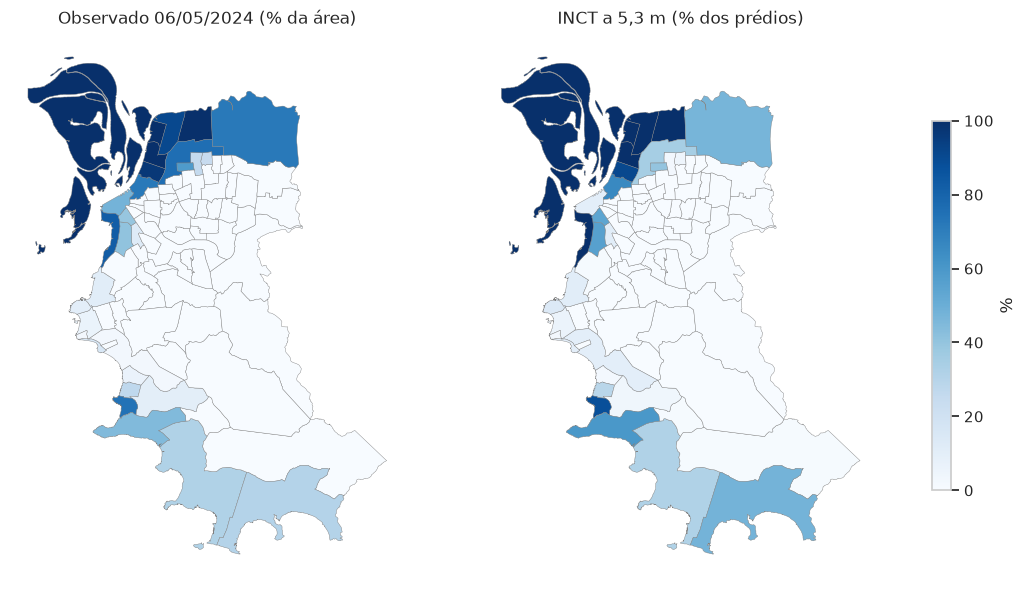

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, (coluna, titulo) in zip(axes, [("obs 2024", "Observado 06/05/2024 (% da área)"),
                                       ("INCT 5,3m", "INCT a 5,3 m (% dos prédios)")]):
    comp.plot(column=coluna, ax=ax, cmap="Blues", vmin=0, vmax=100, edgecolor="gray", linewidth=0.3)
    ax.set_title(titulo)
    ax.set_axis_off()
fig.colorbar(plt.cm.ScalarMappable(cmap="Blues", norm=plt.Normalize(0, 100)), ax=axes, shrink=0.6, label="%")
plt.show()

**Leitura:** correlação alta (~0,96): INCT e mancha observada concordam sobre **quais** bairros alagam.
Pontos abaixo da diagonal são bairros em que a água cobriu mais área do que a fração de prédios afetados no INCT
(ex.: áreas alagadas com poucos prédios). Correlação ≠ causalidade: as duas medidas sobem juntas porque dependem
da mesma coisa — a altitude do bairro.

## Quais bairros alagam sempre? (binarização)

**Binarização por limiar:** o bairro "alagou" (1) se mais de 1% da área ficou sob água; senão 0.
Somando os 1 das 6 cheias, sabemos em quantas cheias cada bairro alagou.

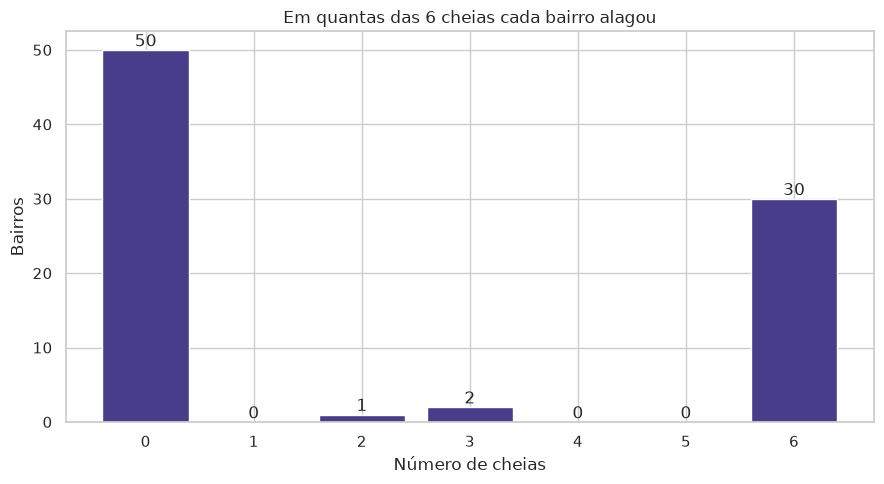

Alagaram em 2024 mas em nenhuma cheia recente (1967, 2015, 2023): ['Santa Cecília']


In [29]:
LIMIAR = 1  # %
binario = (comp[cheias] > LIMIAR).astype(int)
binario["n_cheias"] = binario[cheias].sum(axis=1)

contagem = binario["n_cheias"].value_counts().reindex(range(7), fill_value=0)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(contagem.index, contagem.values, color="darkslateblue")
for x, y in zip(contagem.index, contagem.values):
    ax.text(x, y + 0.5, str(y), ha="center")
ax.set_title("Em quantas das 6 cheias cada bairro alagou")
ax.set_xlabel("Número de cheias")
ax.set_ylabel("Bairros")
plt.tight_layout()
plt.show()

recentes = ["1967", "2015", "set/2023", "nov/2023"]
novos = comp.loc[(binario["2024"] == 1) & (binario[recentes].sum(axis=1) == 0), "bairro"].tolist()
print("Alagaram em 2024 mas em nenhuma cheia recente (1967, 2015, 2023):", novos)

## Pontos de nível medidos em campo

Camada `poa_pontos_nivel`: pontos onde a equipe do GPDEN/IPH/UFRGS marcou **a borda da água** em maio de 2024,
com o nível do Guaíba no dia (`Nivel_G_m`). Primeiro conferimos tipos, faltantes e duplicatas.

In [25]:
pontos = gpd.read_file(GPKG, layer="poa_pontos_nivel")
pontos.info()
print("\nLinhas duplicadas:", pontos.duplicated(subset=["X", "Y", "Data"]).sum())

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 219 entries, 0 to 218
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   X          219 non-null    float64 
 1   Y          219 non-null    float64 
 2   Local      219 non-null    str     
 3   Data       219 non-null    str     
 4   Nivel_G_m  219 non-null    str     
 5   Grupo      219 non-null    str     
 6   Equipe     219 non-null    str     
 7   geometry   219 non-null    geometry
dtypes: float64(2), geometry(1), str(5)
memory usage: 13.8 KB

Linhas duplicadas: 0


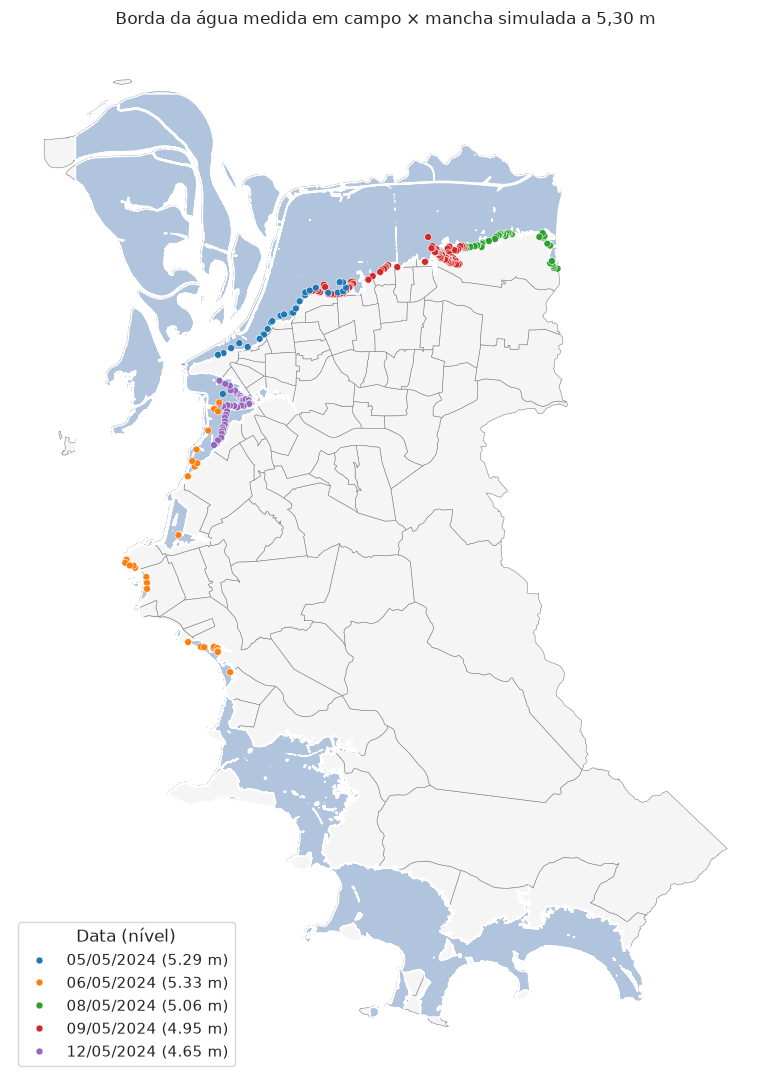

In [21]:
fig, ax = plt.subplots(figsize=(10, 11))
bairros.plot(ax=ax, color="whitesmoke", edgecolor="gray", linewidth=0.4)
gpd.GeoSeries([manchas["2024"]], crs=bairros.crs).clip(bairros.union_all()).plot(ax=ax, color="lightsteelblue")
sns.scatterplot(x=pontos.geometry.x, y=pontos.geometry.y, hue=pontos["dia"], hue_order=sorted(pontos["dia"].unique()), palette="tab10", s=25, ax=ax)
ax.set_title("Borda da água medida em campo × mancha simulada a 5,30 m")
ax.legend(title="Data (nível)", loc="lower left")
ax.set_axis_off()
plt.tight_layout()
plt.show()

**Leitura:**
* 05 e 06/05 (5,29–5,33 m): quase todos os pontos ficam dentro da mancha de 5,30 m, perto da borda.
* 08/05 (5,06 m, Sarandi): quase todos ficam **fora** da mancha de 5,00 m — a água real foi além da simulada.
* 12/05 (4,65 m): comparado com a mancha de 4,75 m (nível maior), então é esperado que fiquem dentro.

## Limitações
* As manchas históricas e a de 5,30 m são **simuladas**; só a do satélite (06/05/2024) é observada.
* % de área alagada e % de prédios afetados (INCT) são medidas diferentes: compare a tendência, não o valor.
* 11 bairros novos do INCT não têm polígono no GeoPackage e ficaram fora.

# Limpeza e exportação dos dados

Esta seção aplica, do zero, todos os tratamentos encontrados na análise e salva o resultado em
`dados/processados/zenodo/` em **formato longo** (uma linha por observação), como o JSON do INCT.
Ela só depende das células de leitura e de limpeza dos nomes (início do notebook).

| Tratamento | Por quê |
|---|---|
| Nome do bairro padronizado e corrigido (`padroniza` + `NOMES_CORRIGIDOS`) | formatos inconsistentes entre GeoPackage e INCT |
| Coluna `bairro` com o nome **como no INCT** | para juntar direto com o JSON do INCT |
| `force_2d()` | remover a coordenada Z, que não usamos |
| `to_crs(EPSG:31982)` | áreas e distâncias em metros |
| `make_valid()` | corrigir polígonos inválidos antes da interseção |
| Recorte da mancha observada para Porto Alegre | a camada cobre toda a bacia do Guaíba |
| `Nivel_G_m` texto → número; `Data` texto → data | tipos corretos |
| Binarização `alagou` (> 1% da área) | mesma regra da análise |
| Outliers **mantidos** | são bairros da orla/ilhas, não erros |
| 11 bairros novos do INCT **não aparecem** | não têm polígono no GeoPackage (dado faltante) |

In [30]:
SAIDA = PROJECT_DIR / "dados" / "processados" / "zenodo"
SAIDA.mkdir(parents=True, exist_ok=True)

# Manchas usadas na análise: (nome da cheia, nível do Guaíba em m, tipo, camada)
MANCHAS = [
    ("1941",     4.75, "simulada",  "poa_inundacao_1941_475cm"),
    ("1967",     3.13, "simulada",  "poa_inundacao_1967_313cm"),
    ("2015",     2.94, "simulada",  "poa_inundacao_2015_294cm"),
    ("set/2023", 3.18, "simulada",  "poa_inundacao_2023_set_318cm"),
    ("nov/2023", 3.46, "simulada",  "poa_inundacao_2023_nov_346cm"),
    ("2024",     5.30, "simulada",  "poa_inundacao_2024_530cm"),
    # ALTERAÇÃO: a camada observada não informa o nível; usamos 5,33 m, nível do Guaíba
    # registrado em 06/05/2024 na camada poa_pontos_nivel (mesmo dia das imagens).
    ("obs 2024", 5.33, "observada", "rhguaiba_planet-skysat_inundacao_obs_20240506"),
]
LIMIAR = 1  # % da área para considerar que o bairro alagou

# Bairros limpos
b = bairros[["nmbop", "chave", "geometry"]].copy()
b = b.to_crs(31982)                 # ALTERAÇÃO: CRS em metros (a camada já vem em 31982; garante)
b["geometry"] = b.force_2d()        # ALTERAÇÃO: remove coordenada Z
b["area_km2"] = b.area / 1e6

# ALTERAÇÃO: nome do bairro como escrito no INCT (todos os 83 bairros do GeoPackage existem no INCT)
nome_inct = inct.drop_duplicates("chave").set_index("chave")["bairro"]
b["bairro"] = b["chave"].map(nome_inct)
assert b["bairro"].notna().all(), "algum bairro do GeoPackage não foi encontrado no INCT"

In [31]:
linhas = []
for cheia, nivel, tipo, camada in MANCHAS:
    mancha = gpd.read_file(GPKG, layer=camada).to_crs(b.crs)   # ALTERAÇÃO: CRS em metros
    mancha["geometry"] = mancha.force_2d()                        # ALTERAÇÃO: remove coordenada Z
    mancha = mancha.make_valid()                                  # ALTERAÇÃO: corrige polígonos inválidos
    if tipo == "observada":
        mancha = gpd.clip(mancha, b.total_bounds)                 # ALTERAÇÃO: recorta para Porto Alegre
    mancha = mancha.union_all()

    area_alagada = b.intersection(mancha).area / 1e6
    linhas.append(pd.DataFrame({
        "cheia": cheia,
        "nivel_m": nivel,
        "tipo_mancha": tipo,
        "camada": camada,
        "bairro": b["bairro"],
        "nome_geopackage": b["nmbop"],
        "area_bairro_km2": b["area_km2"].round(4),
        "area_alagada_km2": area_alagada.round(4),
        "pct_area_alagada": (area_alagada / b["area_km2"] * 100).round(2),
    }))

alagamento = pd.concat(linhas, ignore_index=True)
alagamento["alagou"] = (alagamento["pct_area_alagada"] > LIMIAR).astype(int)  # binarização

print(alagamento.shape)  # 7 manchas x 83 bairros = 581 linhas
alagamento.head()

(581, 10)


,cheia,nivel_m,tipo_mancha,camada,bairro,nome_geopackage,area_bairro_km2,area_alagada_km2,pct_area_alagada,alagou
0,1941,4.75,simulada,poa_inundacao_1941_475cm,Agronomia,AGRONOMIA,16.6367,0.0000,0.00,0
1,1941,4.75,simulada,poa_inundacao_1941_475cm,Anchieta,ANCHIETA,5.2560,5.1030,97.09,1
2,1941,4.75,simulada,poa_inundacao_1941_475cm,Arquipélago,ARQUIPELAGO,44.2220,42.0352,95.05,1
3,1941,4.75,simulada,poa_inundacao_1941_475cm,Auxiliadora,AUXILIADORA,0.8448,0.0000,0.00,0
4,1941,4.75,simulada,poa_inundacao_1941_475cm,Azenha,AZENHA,1.1520,0.2619,22.74,1


In [32]:
# Verificações
assert len(alagamento) == len(MANCHAS) * len(b)
assert not alagamento.duplicated(["cheia", "bairro"]).any()
assert alagamento["pct_area_alagada"].between(0, 100.01).all()
assert alagamento.notna().all().all()

def salva_json(df, caminho):
    """Salva no formato longo: lista com um objeto por linha."""
    with open(caminho, "w", encoding="utf-8") as f:
        json.dump(df.to_dict(orient="records"), f, ensure_ascii=False, indent=1)

salva_json(alagamento, SAIDA / "alagamento_bairros.json")
print("Salvo:", SAIDA / "alagamento_bairros.json")

Salvo: /home/piedrorn/Documentos/puc/coleta/projeto-enchentes/dados/processados/zenodo/alagamento_bairros.json


### Pontos de nível medidos em campo

Uma linha por ponto. Coordenadas em graus (lat/lon) para usar direto em mapas, e o bairro onde o ponto caiu.

In [33]:
pts = gpd.read_file(GPKG, layer="poa_pontos_nivel")
pts["geometry"] = pts.force_2d()                                     # ALTERAÇÃO: remove coordenada Z
pts["Nivel_G_m"] = pts["Nivel_G_m"].astype(float)                    # ALTERAÇÃO: texto -> número
pts["Data"] = pd.to_datetime(pts["Data"], format="%d/%m/%Y")         # ALTERAÇÃO: texto -> data

# ALTERAÇÃO: bairro de cada ponto (junção espacial com os bairros, no mesmo CRS)
pts = gpd.sjoin(pts.to_crs(b.crs), b[["bairro", "geometry"]], how="left", predicate="within")
pts = pts.to_crs(4326)

pontos_limpos = pd.DataFrame({
    "data": pts["Data"].dt.strftime("%Y-%m-%d"),
    "nivel_m": pts["Nivel_G_m"],
    "local": pts["Local"],
    "bairro": pts["bairro"],
    "lat": pts.geometry.y.round(6),
    "lon": pts.geometry.x.round(6),
    "grupo": pts["Grupo"],
    "equipe": pts["Equipe"],
}).sort_values(["data", "local"]).reset_index(drop=True)

assert not pontos_limpos.duplicated(["lat", "lon", "data"]).any()
print("Pontos sem bairro (fora dos polígonos):", pontos_limpos["bairro"].isna().sum())

salva_json(pontos_limpos, SAIDA / "pontos_nivel.json")
print("Salvo:", SAIDA / "pontos_nivel.json", pontos_limpos.shape)
pontos_limpos.head()

Pontos sem bairro (fora dos polígonos): 0
Salvo: /home/piedrorn/Documentos/puc/coleta/projeto-enchentes/dados/processados/zenodo/pontos_nivel.json (219, 8)


,data,nivel_m,local,bairro,lat,lon,grupo,equipe
0,2024-05-05,5.29,Centro_Historico,Centro Histórico,-30.026799,-51.222518,GPDEN/IPH/UFRGS,Gonzales-avila; Michel; Kobiyama
1,2024-05-05,5.29,Centro_Historico,Centro Histórico,-30.028597,-51.225641,GPDEN/IPH/UFRGS,Gonzales-avila; Michel; Kobiyama
2,2024-05-05,5.29,Centro_Historico,Centro Histórico,-30.029204,-51.227896,GPDEN/IPH/UFRGS,Gonzales-avila; Michel; Kobiyama
3,2024-05-05,5.29,Floresta,Floresta,-30.023446,-51.210880,GPDEN/IPH/UFRGS,Gonzales-avila; Michel; Kobiyama
4,2024-05-05,5.29,Floresta,Floresta,-30.021768,-51.209325,GPDEN/IPH/UFRGS,Gonzales-avila; Michel; Kobiyama
